# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   Thomas Brady
 2.   Mirella Yana
 3.    
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025.csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [2]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

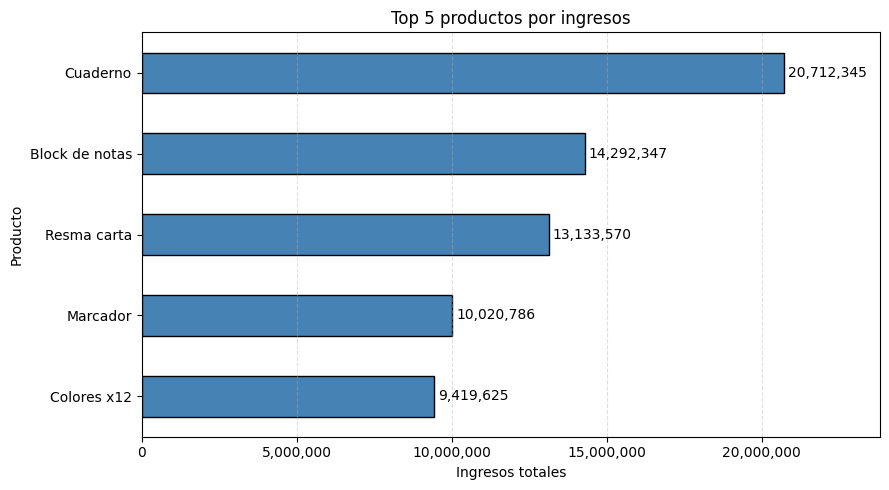

,total
producto,
Cuaderno,20712345
Block de notas,14292347
Resma carta,13133570
Marcador,10020786
Colores x12,9419625


In [3]:
# Ejercicio 1
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1) Tabla: ingresos por producto, top 5
top_productos = (
    df.groupby("producto")["total"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

# 2) Gráfico de barras horizontales (el mayor arriba)
ax = top_productos.sort_values().plot(
    kind="barh",
    title="Top 5 productos por ingresos",
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

# 3) Etiquetas y formato
ax.set_xlabel("Ingresos totales")
ax.set_ylabel("Producto")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}" for v in top_productos.sort_values()], padding=3)
ax.set_xlim(0, top_productos.max() * 1.15)  # espacio para las etiquetas
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Mostrar la tabla final
top_productos

In [4]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")


Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

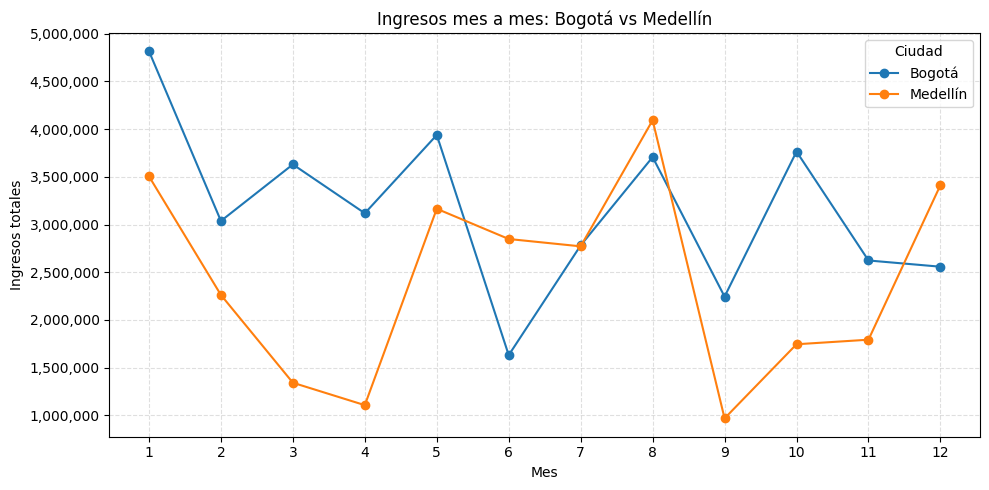

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


In [5]:
# Ejercicio 2
# Ejercicio 2
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1) Filtrar solo Bogotá y Medellín
df_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

# 2) Tabla dinámica: meses en filas, ciudades en columnas, suma de total
ing_mes_ciudad = df_ciudades.pivot_table(
    index="mes",
    columns="ciudad",
    values="total",
    aggfunc="sum"
)

# 3) Gráfico de líneas con marcadores
ax = ing_mes_ciudad.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Ingresos mes a mes: Bogotá vs Medellín"
)

# 4) Etiquetas y formato
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos totales")
ax.set_xticks(ing_mes_ciudad.index)                      # un tick por mes
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.legend(title="Ciudad")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Mostrar la tabla final
ing_mes_ciudad

In [6]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

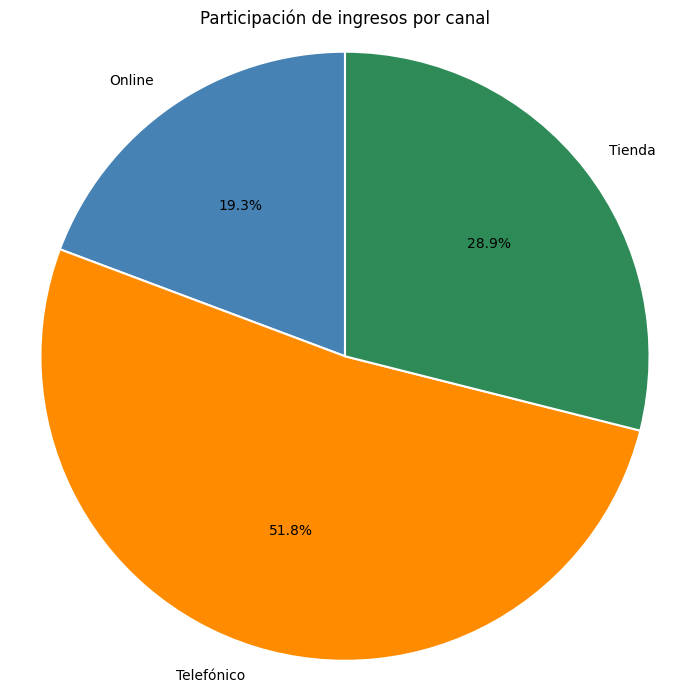

,total
canal,
Online,22887574
Telefónico,61450716
Tienda,34329722


In [7]:
# Ejercicio 3
# Ejercicio 3
import matplotlib.pyplot as plt

# 1) Ingresos totales por canal
ing_canal = df.groupby("canal")["total"].sum()

# 2) Gráfico de pie con porcentajes de un decimal
ax = ing_canal.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    figsize=(7, 7),
    title="Participación de ingresos por canal",
    colors=["steelblue", "darkorange", "seagreen", "indianred"][:len(ing_canal)],
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

# 3) Limpieza del gráfico
ax.set_ylabel("")   # quita la etiqueta "total" que pandas pone al costado
ax.axis("equal")    # círculo perfecto

plt.tight_layout()
plt.show()

# Mostrar la tabla final
ing_canal

In [8]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

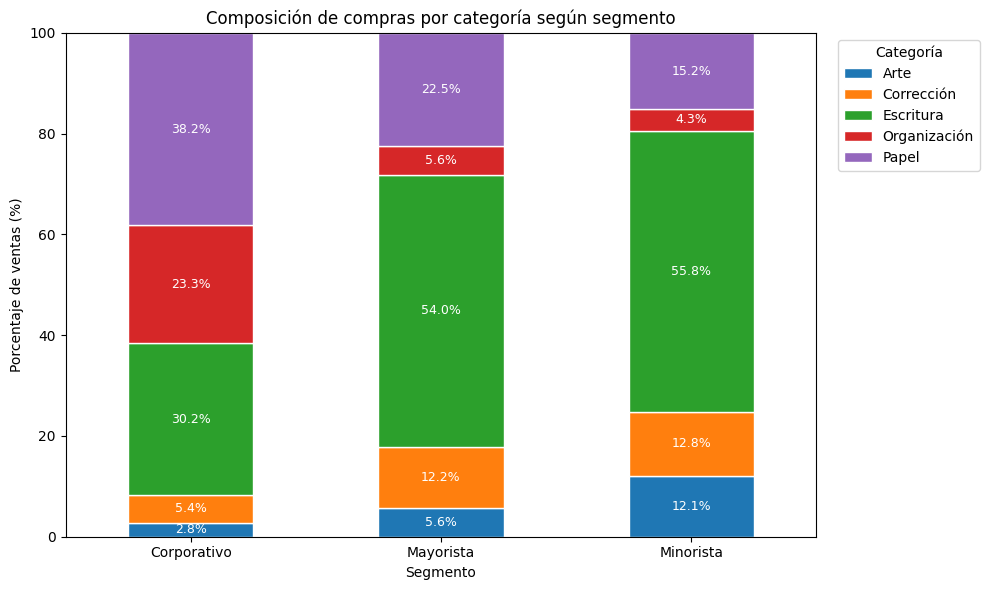

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.807775,5.399568,30.237581,23.326134,38.228942
Mayorista,5.623472,12.224939,54.034230,5.623472,22.493888
Minorista,12.056738,12.765957,55.762411,4.255319,15.159574


In [9]:
# Ejercicio 4
# Ejercicio 4
import matplotlib.pyplot as plt

# 1) Crosstab normalizado por fila, en porcentaje (0 a 100)
tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

# 2) Barras apiladas
ax = tabla_seg_cat.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    title="Composición de compras por categoría según segmento",
    edgecolor="white"
)

# 3) Etiquetas y formato
ax.set_xlabel("Segmento")
ax.set_ylabel("Porcentaje de ventas (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc="upper left")

# Porcentaje dentro de cada tramo
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[f"{v:.1f}%" for v in contenedor.datavalues],
                 label_type="center", fontsize=9, color="white")

plt.tight_layout()
plt.show()

# Mostrar la tabla final
tabla_seg_cat

In [10]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

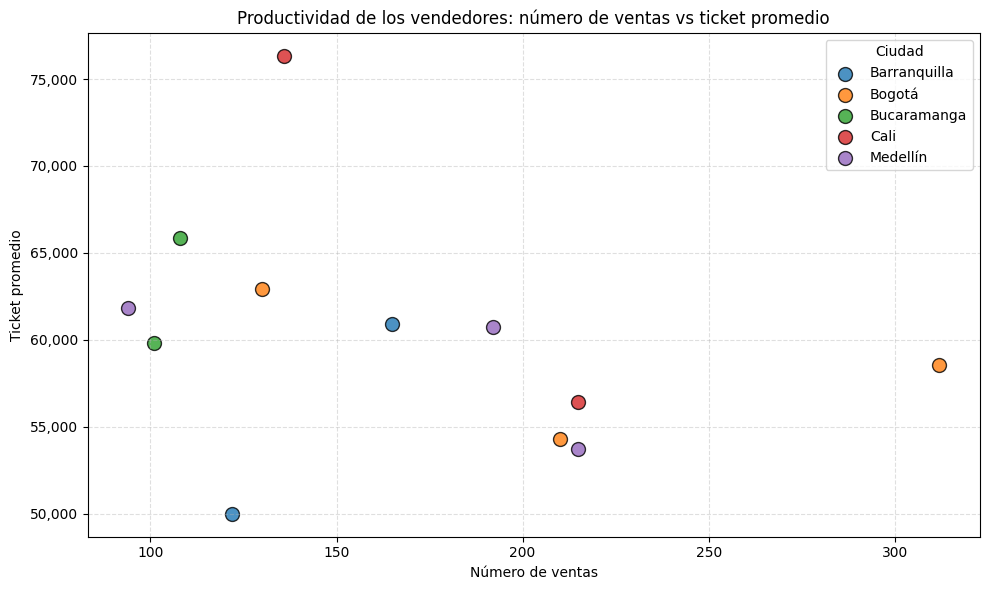

,vendedor,ciudad,n_ventas,ticket_prom
0,Andrés Rojas,Medellín,192,60729.104167
1,Camilo Pardo,Bogotá,210,54276.595238
2,Daniela Ríos,Bogotá,130,62903.423077
3,Esteban Uribe,Medellín,94,61833.978723
4,Isabela Mora,Bucaramanga,108,65873.037037
5,Julián Cortés,Cali,215,56389.920930
6,Laura Gómez,Bogotá,312,58564.371795
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
9,Santiago Duarte,Bucaramanga,101,59798.841584


In [11]:
# Ejercicio 5
# Ejercicio 5
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1) Número de ventas y ticket promedio por vendedor y ciudad
vend = (
    df.groupby(["vendedor", "ciudad"])
      .agg(
          n_ventas=("total", "count"),
          ticket_prom=("total", "mean")
      )
      .reset_index()
)

# 2) Dispersión: un color por ciudad (scatter dentro de un for)
fig, ax = plt.subplots(figsize=(10, 6))

for ciudad, grupo in vend.groupby("ciudad"):
    ax.scatter(
        grupo["n_ventas"],
        grupo["ticket_prom"],
        label=ciudad,
        s=100,
        alpha=0.8,
        edgecolor="black"
    )

# 3) Etiquetas y formato
ax.set_title("Productividad de los vendedores: número de ventas vs ticket promedio")
ax.set_xlabel("Número de ventas")
ax.set_ylabel("Ticket promedio")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.legend(title="Ciudad")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Mostrar la tabla final
vend

In [12]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

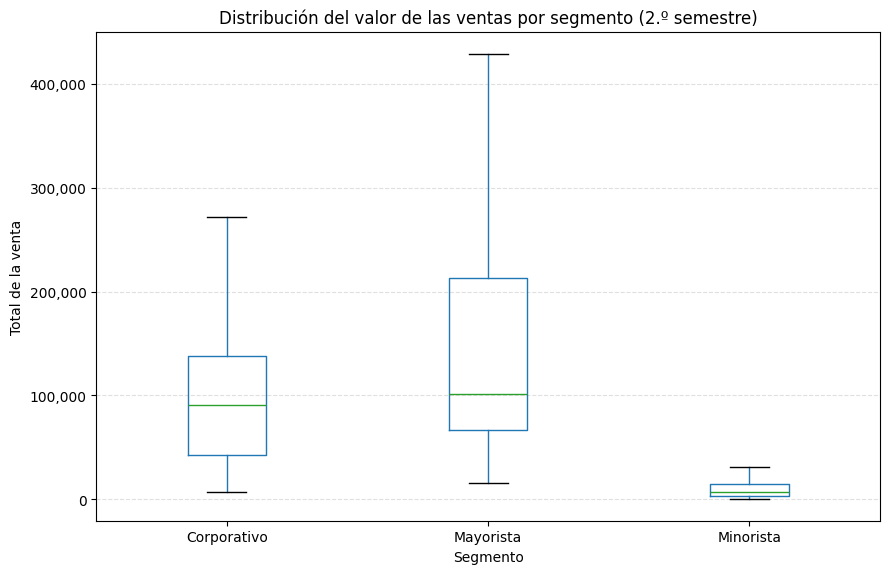

1050

In [13]:
# Ejercicio 6
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1) Filtrar el segundo semestre (meses 7 a 12)
sem2 = df[df["mes"] >= 7]

# 2) Diagrama de cajas del total por segmento, sin atípicos
ax = sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    figsize=(9, 6),
    grid=False
)

# 3) Título y etiquetas
plt.suptitle("")   # quita el título automático "Boxplot grouped by segmento"
ax.set_title("Distribución del valor de las ventas por segmento (2.º semestre)")
ax.set_xlabel("Segmento")
ax.set_ylabel("Total de la venta")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Mostrar cuántas ventas quedaron
len(sem2)

In [14]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [15]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# --- [0, 0] Top 5 productos (barras horizontales) ---
top_productos = (
    df.groupby("producto")["total"].sum()
      .sort_values(ascending=False).head(5)
)
top_productos.sort_values().plot(
    kind="barh", ax=axs[0, 0], color="steelblue", edgecolor="black",
    title="Top 5 productos por ingresos"
)
axs[0, 0].set_xlabel("Ingresos totales")
axs[0, 0].set_ylabel("Producto")
axs[0, 0].xaxis.set_major_formatter(miles)

# --- [0, 1] Bogotá vs Medellín mes a mes (líneas) ---
ing_mes_ciudad = (
    df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
)
ing_mes_ciudad.plot(
    kind="line", marker="o", ax=axs[0, 1],
    title="Ingresos mes a mes: Bogotá vs Medellín"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos totales")
axs[0, 1].set_xticks(ing_mes_ciudad.index)
axs[0, 1].yaxis.set_major_formatter(miles)
axs[0, 1].legend(title="Ciudad")
axs[0, 1].grid(True, linestyle="--", alpha=0.4)

# --- [0, 2] Participación por canal (pie) ---
ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot(
    kind="pie", ax=axs[0, 2], autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    title="Participación de ingresos por canal"
)
axs[0, 2].set_ylabel("")

# --- [1, 0] Composición por segmento (barras apiladas) ---
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot(
    kind="bar", stacked=True, ax=axs[1, 0], edgecolor="white",
    title="Compras por categoría según segmento"
)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje de ventas (%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8)

# --- [1, 1] Productividad de vendedores (dispersión) ---
vend = (
    df.groupby(["vendedor", "ciudad"])
      .agg(n_ventas=("total", "count"), ticket_prom=("total", "mean"))
      .reset_index()
)
for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"],
                      label=ciudad, s=100, alpha=0.8, edgecolor="black")
axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio")
axs[1, 1].yaxis.set_major_formatter(miles)
axs[1, 1].legend(title="Ciudad")
axs[1, 1].grid(True, linestyle="--", alpha=0.4)

# --- [1, 2] Boxplot por segmento, 2.º semestre ---
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False,
             ax=axs[1, 2], grid=False)
axs[1, 2].set_title("Valor de las ventas por segmento (2.º semestre)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total de la venta")
axs[1, 2].yaxis.set_major_formatter(miles)

# --- Título general y ajuste ---
fig.suptitle("Panel de ventas: resumen general", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

Writing figura_base.py


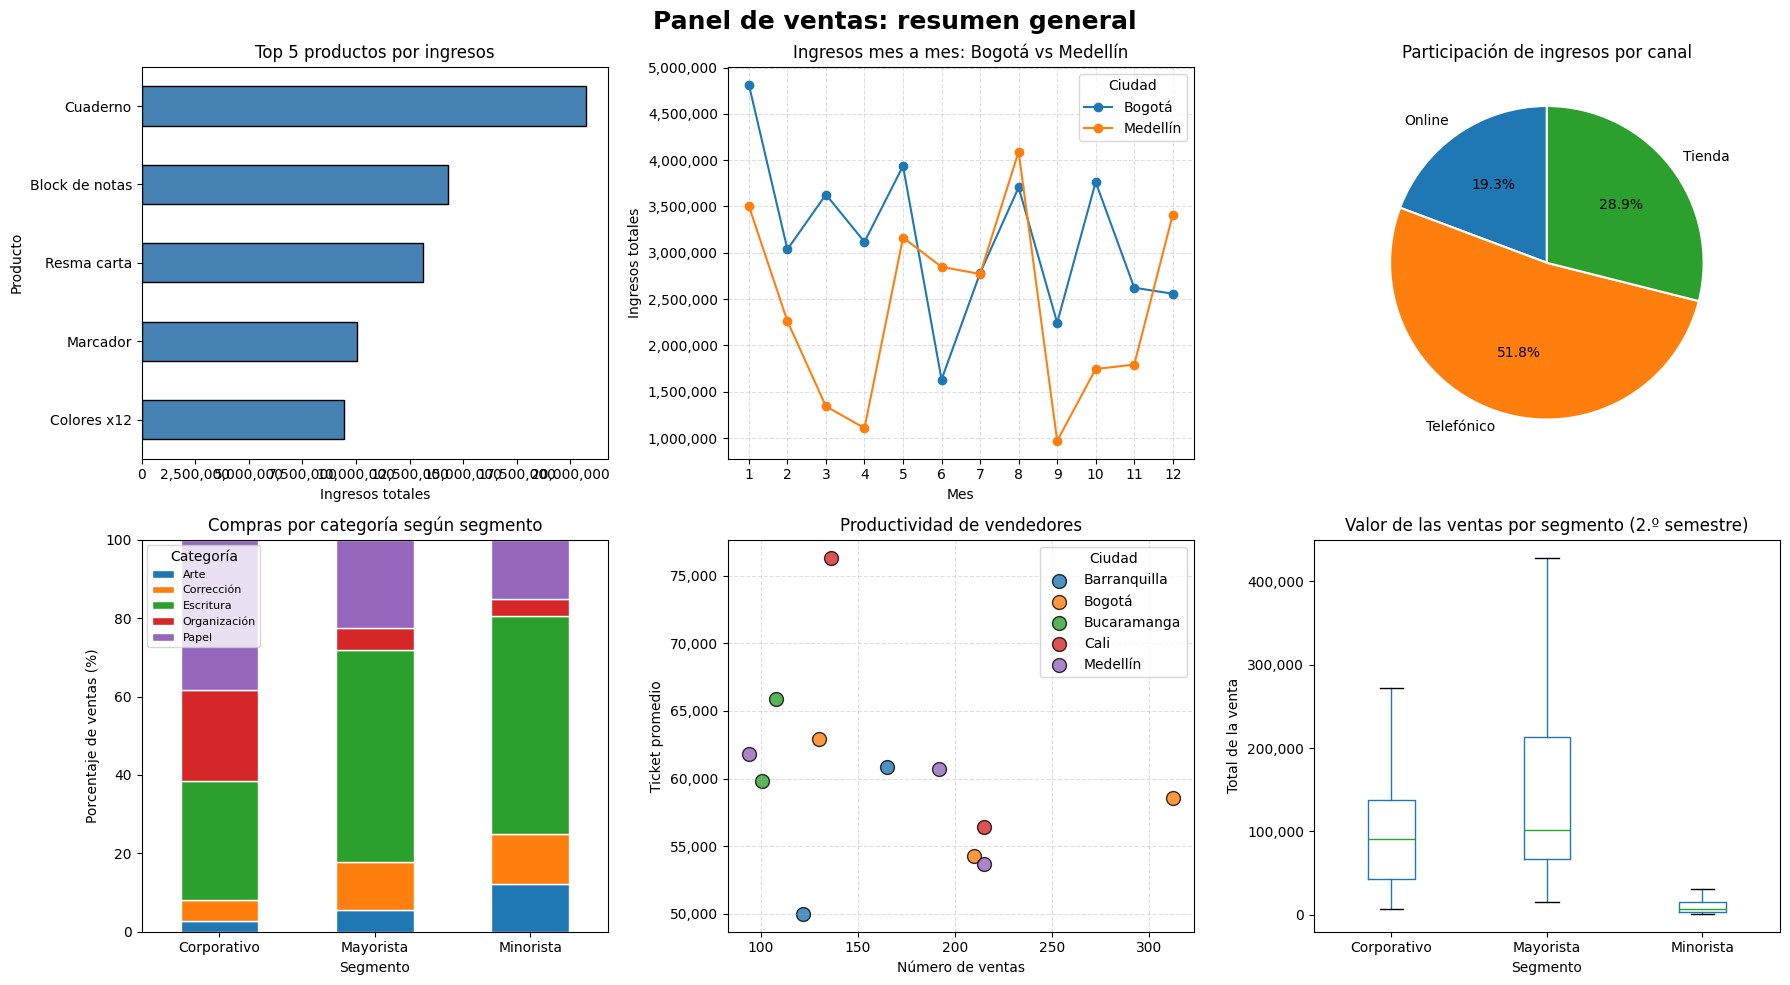

<Figure size 640x480 with 0 Axes>

In [16]:
%run -i figura_base.py

In [17]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [18]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# --- [0, 0] Top 5 productos (barras horizontales) ---
top_productos = (
    df.groupby("producto")["total"].sum()
      .sort_values(ascending=False).head(5)
)
top_productos.sort_values().plot(
    kind="barh", ax=axs[0, 0], color="steelblue", edgecolor="black",
    title="Top 5 productos por ingresos"
)
axs[0, 0].set_xlabel("Ingresos totales")
axs[0, 0].set_ylabel("Producto")
axs[0, 0].xaxis.set_major_formatter(miles)

# --- [0, 1] Bogotá vs Medellín mes a mes (líneas) ---
ing_mes_ciudad = (
    df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
)
ing_mes_ciudad.plot(
   

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [19]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La figura la verá la junta directiva de una cadena de papelerías (gerente general, gerente de compras y dirección regional), proyectada en una sala de reuniones. Debe leerse en 30 segundos y dejar claras las decisiones: qué productos priorizar, qué canal reforzar y en qué ciudades y segmentos concentrarse. Estilo de dashboard ejecutivo, limpio y profesional.

PALETA Y TIPOGRAFÍA: Fondo gris azulado muy claro (#F7F9FC) en toda la figura. Azul oscuro (#1F3A5F) para títulos y para resaltar lo más importante, azul (#2E75B6) y naranja (#F28E2B) como colores principales; verde, morado y rojo suaves para las demás categorías. Usa siempre el mismo color para la misma ciudad (Bogotá azul, Medellín naranja). Fuente sans-serif, texto general de 11 pt, títulos de cada gráfico en negrita de 13 pt alineados a la izquierda, y un título general grande (22 pt, negrita, alineado a la izquierda) con un subtítulo gris que diga los ingresos totales y el número de ventas.

TÍTULOS: Cada gráfico debe tener un título que diga la CONCLUSIÓN y se calcule con los datos (no escribas cifras a mano), por ejemplo: "Cuaderno lidera: 17% de los ingresos", "Telefónico concentra 52% de los ingresos", "Bogotá supera a Medellín en ingresos del año", "Papel pesa más en Corporativo", "Laura Gómez lidera con 312 ventas". Que el título del boxplot sea corto para que no se corte.

EJES Y NÚMEROS: Los ingresos se muestran como "$ 12 M" (millones) en los ejes y como "$ 20,7 M" sobre las barras; los tickets y totales de venta con separador de miles y signo $. Etiquetas de ejes claras y cortas, meses como números del 1 al 12, porcentajes con un decimal en el pie y sin decimales dentro de las barras apiladas. Etiqueta el valor sobre cada barra del Top 5 y dentro de cada tramo apilado que pese 8 % o más.

LIMPIEZA VISUAL: Quita el borde superior y derecho de todos los gráficos, usa una cuadrícula gris muy suave solo en el eje que ayuda a leer, sin bordes negros en barras ni puntos. En el Top 5 resalta la barra líder con el azul oscuro. Pon la leyenda de las barras apiladas debajo del gráfico para que no tape nada, deja la leyenda de ciudades sin marco y deja espacio entre gráficos para que nada se superponga.
"""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO: La figura la verá la junta directiva de una cadena de papelerías (gerente general, gerente de compras y dirección regional), proyectada en una sala de reuniones. Debe leerse en 30 segundos y dejar claras las decisiones: qué productos priorizar, qué canal reforzar y en qué ciudades y segmentos concentrarse. Estilo de dashboard ejecutivo, limpio y profesional.

PALETA Y TIPOGRAFÍA: Fondo gris azulado muy claro (#F7F9FC) en toda la figura. Azul oscuro (#1F3A5F) para títulos y para resaltar lo más importante, azul (#2E75B6) y naranja (#F28E2B) como colores principales; verde, morado y rojo suaves para las demás categorías. Usa siempre el mismo color para la misma ciudad (Bogotá azul, Medellín naranja). Fuente sans-serif, texto general de 11 pt, títulos de cada gráfico en negrita de 13 pt alineados a la izquierda, y un título general grande (22 pt, negrita, alineado a la izquierda) con un subtítulo gris que diga los ingresos totales y el número de ventas.

TÍTULOS: Cada

In [20]:
%%writefile figura_v1.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Paleta y estilo ----------
AZUL_OSC, AZUL, NARANJA = "#1F3A5F", "#2E75B6", "#F28E2B"
VERDE, MORADO, ROJO, GRIS = "#3BAA8C", "#9B6BCC", "#E15759", "#6B7280"
FONDO, TEXTO = "#F7F9FC", "#1F2937"
CICLO = [AZUL, NARANJA, VERDE, MORADO, ROJO, "#8C8C8C"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": GRIS, "axes.edgecolor": "#D1D5DB",
    "axes.facecolor": FONDO, "figure.facecolor": FONDO,
    "xtick.color": GRIS, "ytick.color": GRIS, "text.color": TEXTO,
})

millones = FuncFormatter(lambda v, _: f"$ {v/1e6:,.0f} M")
millones1 = FuncFormatter(lambda v, _: f"$ {v/1e6:,.1f} M")
miles = FuncFormatter(lambda v, _: f"$ {v:,.0f}")

def limpiar(ax, eje="y"):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.grid(axis=eje, color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)

total_global = df["total"].sum()
fig, axs = plt.subplots(2, 3, figsize=(20, 11))
fig.patch.set_facecolor(FONDO)

# --- [0, 0] Top 5 productos ---
top = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
t = top.sort_values()
barras = axs[0, 0].barh(t.index, t.values, color=AZUL, edgecolor="none", height=0.65)
barras[-1].set_color(AZUL_OSC)
for b, v in zip(barras, t.values):
    axs[0, 0].text(v + t.max() * 0.015, b.get_y() + b.get_height() / 2,
                   f"$ {v/1e6:,.1f} M", va="center", fontsize=10, color=TEXTO)
axs[0, 0].set_xlim(0, t.max() * 1.22)
axs[0, 0].xaxis.set_major_formatter(millones)
axs[0, 0].set_title(f"{top.index[0]} lidera: {top.iloc[0]/total_global:.0%} de los ingresos")
axs[0, 0].set_xlabel("Ingresos totales")
limpiar(axs[0, 0], "x")
axs[0, 0].spines["left"].set_visible(False)

# --- [0, 1] Bogotá vs Medellín mes a mes ---
ing = (df[df["ciudad"].isin(["Bogotá", "Medellín"])]
       .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum"))
colores_ciu = {"Bogotá": AZUL, "Medellín": NARANJA}
for ciudad in ing.columns:
    axs[0, 1].plot(ing.index, ing[ciudad], marker="o", linewidth=2.5,
                   color=colores_ciu[ciudad], label=ciudad)
tot_ciu = ing.sum()
axs[0, 1].set_title(f"{tot_ciu.idxmax()} supera a {tot_ciu.idxmin()} en ingresos del año")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos")
axs[0, 1].set_xticks(ing.index)
axs[0, 1].yaxis.set_major_formatter(millones1)
axs[0, 1].legend(frameon=False)
limpiar(axs[0, 1])

# --- [0, 2] Participación por canal ---
canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
axs[0, 2].pie(canal.values, labels=canal.index, autopct="%1.1f%%", startangle=90,
              colors=CICLO[:len(canal)], counterclock=False,
              wedgeprops={"edgecolor": FONDO, "linewidth": 2},
              textprops={"fontsize": 11}, pctdistance=0.72)
axs[0, 2].set_title(f"{canal.index[0]} concentra {canal.iloc[0]/canal.sum():.0%} de los ingresos")
axs[0, 2].axis("equal")

# --- [1, 0] Composición por segmento ---
tabla = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
base = np.zeros(len(tabla))
for i, cat in enumerate(tabla.columns):
    axs[1, 0].bar(tabla.index, tabla[cat], bottom=base, color=CICLO[i % len(CICLO)],
                  edgecolor=FONDO, linewidth=1.5, label=cat, width=0.6)
    for x, (v, b0) in enumerate(zip(tabla[cat], base)):
        if v >= 8:
            axs[1, 0].text(x, b0 + v / 2, f"{v:.0f}%", ha="center", va="center",
                           color="white", fontsize=10, fontweight="bold")
    base += tabla[cat].values
dif = tabla.max() - tabla.min()
cat_clave = dif.idxmax()
seg_clave = tabla[cat_clave].idxmax()
axs[1, 0].set_title(f"{cat_clave} pesa más en {seg_clave} ({tabla.loc[seg_clave, cat_clave]:.0f}%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].set_ylabel("% de las ventas")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(title="Categoría", frameon=False, fontsize=9, title_fontsize=10,
                 loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
limpiar(axs[1, 0])

# --- [1, 1] Productividad de vendedores ---
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("total", "count"), ticket_prom=("total", "mean"))
          .reset_index())
ciudades = sorted(vend["ciudad"].unique())
col_ciudad = {c: colores_ciu.get(c) for c in ciudades}
libres = [c for c in CICLO if c not in colores_ciu.values()]
for c in ciudades:
    if col_ciudad[c] is None:
        col_ciudad[c] = libres.pop(0)
for c, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], s=130, alpha=0.9,
                      color=col_ciudad[c], edgecolor="white", linewidth=1.2, label=c)
lider = vend.loc[vend["n_ventas"].idxmax()]
axs[1, 1].annotate(lider["vendedor"], (lider["n_ventas"], lider["ticket_prom"]),
                   xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=10)
axs[1, 1].set_title(f"{lider['vendedor']} lidera con {int(lider['n_ventas'])} ventas")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio")
axs[1, 1].yaxis.set_major_formatter(miles)
axs[1, 1].legend(title="Ciudad", frameon=False, fontsize=9)
limpiar(axs[1, 1], "both")

# --- [1, 2] Boxplot por segmento, 2.º semestre ---
sem2 = df[df["mes"] >= 7]
segs = sorted(sem2["segmento"].unique())
datos = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = axs[1, 2].boxplot(datos, tick_labels=segs, showfliers=False, patch_artist=True, widths=0.55,
                       medianprops={"color": "white", "linewidth": 2.5},
                       whiskerprops={"color": GRIS}, capprops={"color": GRIS})
for caja, color in zip(bp["boxes"], CICLO):
    caja.set(facecolor=color, edgecolor="none")
medianas = sem2.groupby("segmento")["total"].median()
axs[1, 2].set_title(f"{medianas.idxmax()}: mediana más alta ($ {medianas.max()/1e3:,.0f} mil)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total de la venta")
axs[1, 2].yaxis.set_major_formatter(miles)
limpiar(axs[1, 2])

# --- Encabezado general ---
fig.suptitle("Panel de ventas · Papelerías 2025", fontsize=22, fontweight="bold",
             x=0.02, ha="left", color=AZUL_OSC)
fig.text(0.02, 0.925, f"Ingresos totales $ {total_global/1e6:,.1f} M  ·  {len(df):,} ventas  ·  5 ciudades",
         fontsize=13, color=GRIS)
plt.tight_layout(rect=[0, 0, 1, 0.91])

Writing figura_v1.py


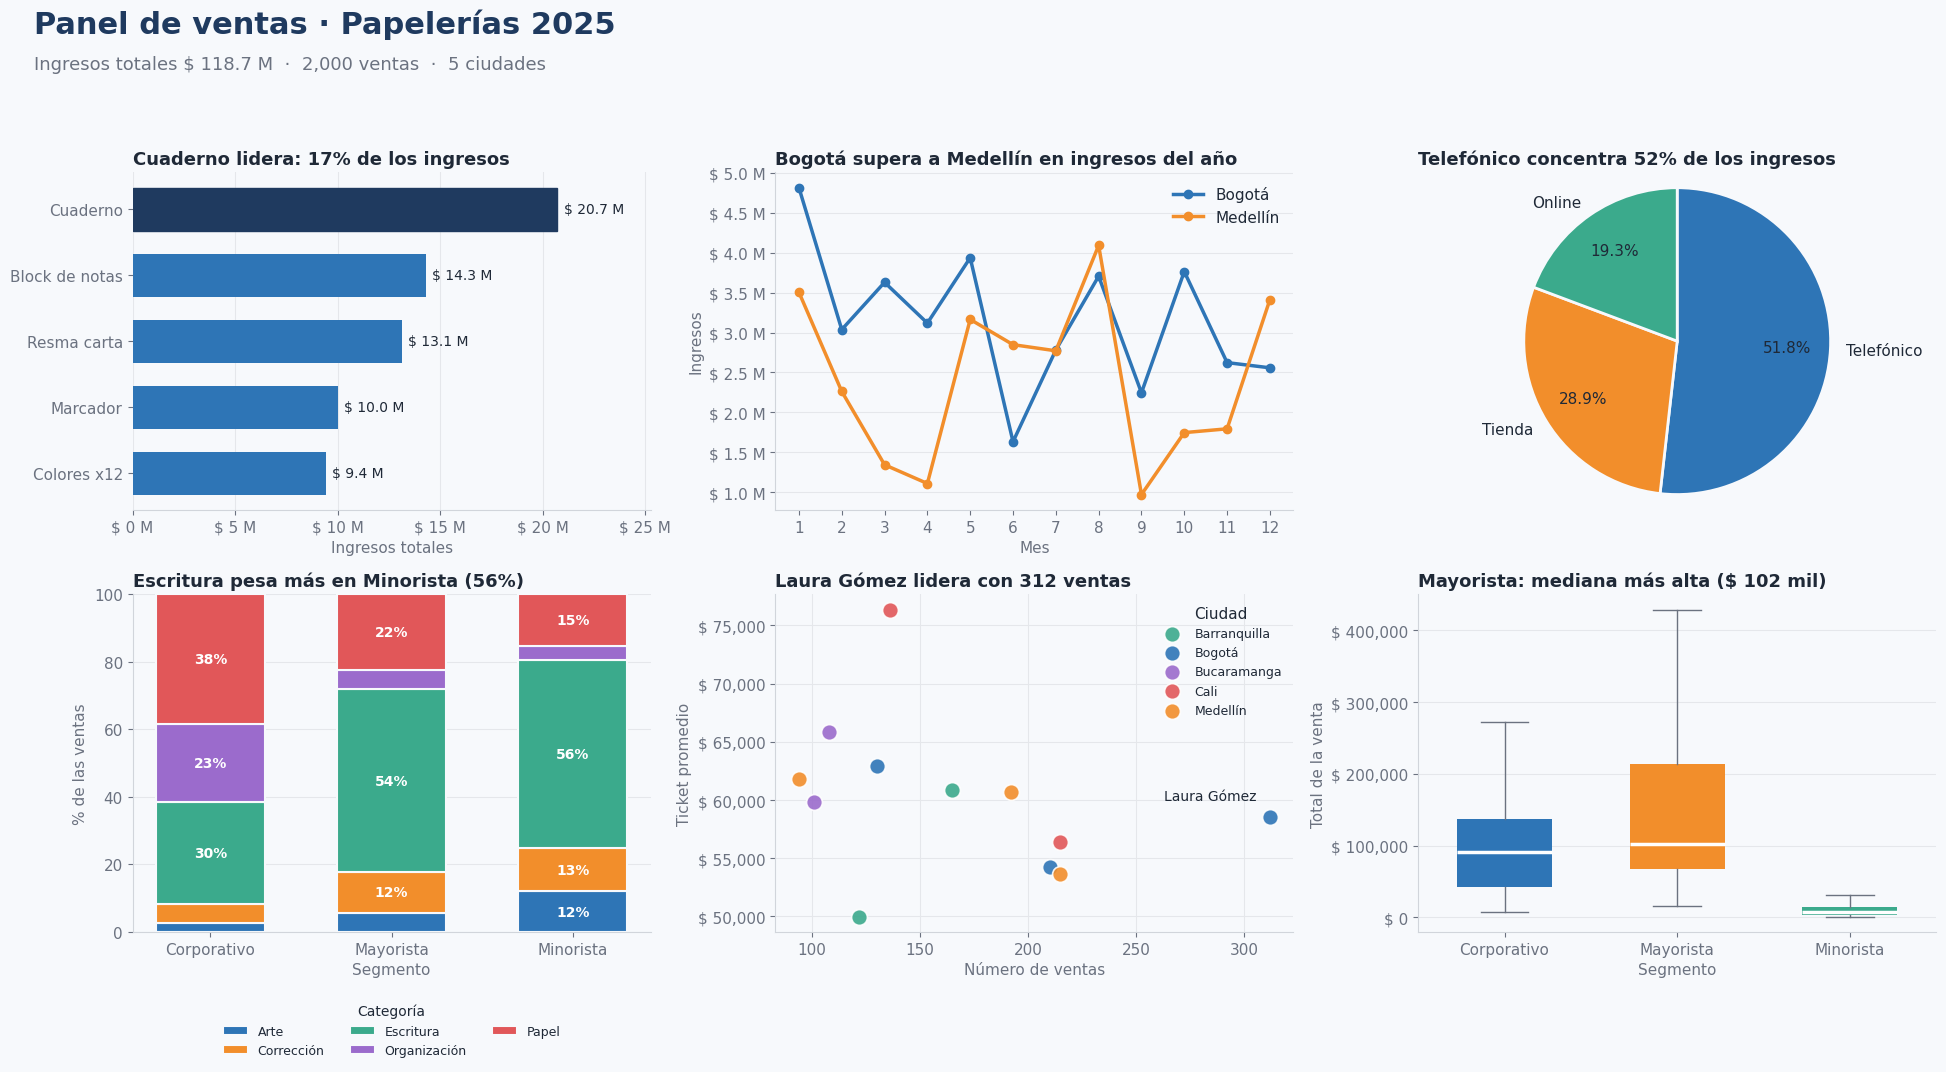

In [21]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [22]:
prompt_v2 = prompt_v1 + """

AJUSTES: Cambios concretos sobre la versión anterior:
1) Paleta nueva: cambia el azul y el naranja por verde azulado (#1B8A8F) y coral (#FF6B5B), usa ámbar (#F4B942) y morado como colores secundarios, y un fondo crema (#FAF7F2). Títulos en verde azulado muy oscuro (#0B3C49).
2) Letras más grandes: texto general de 13 pt, títulos de gráfico de 15 pt, título general de 26 pt y figura más grande (22 x 12 pulgadas).
3) Reemplaza el gráfico de pie de canales por una dona (anillo) y escribe el ingreso total en millones en el centro.
4) En el gráfico de líneas, anota el mes pico de cada ciudad con su valor (por ejemplo "Pico Bogotá: mes 1, $ 4,8 M") con una línea fina que apunte al punto, sin que el texto tape el título.
5) En el Top 5, pinta las 4 barras no líderes en un verde azulado claro (#9CCFD1) y deja solo la líder en tono oscuro.
"""

print(prompt_v2)


PÚBLICO Y OBJETIVO: La figura la verá la junta directiva de una cadena de papelerías (gerente general, gerente de compras y dirección regional), proyectada en una sala de reuniones. Debe leerse en 30 segundos y dejar claras las decisiones: qué productos priorizar, qué canal reforzar y en qué ciudades y segmentos concentrarse. Estilo de dashboard ejecutivo, limpio y profesional.

PALETA Y TIPOGRAFÍA: Fondo gris azulado muy claro (#F7F9FC) en toda la figura. Azul oscuro (#1F3A5F) para títulos y para resaltar lo más importante, azul (#2E75B6) y naranja (#F28E2B) como colores principales; verde, morado y rojo suaves para las demás categorías. Usa siempre el mismo color para la misma ciudad (Bogotá azul, Medellín naranja). Fuente sans-serif, texto general de 11 pt, títulos de cada gráfico en negrita de 13 pt alineados a la izquierda, y un título general grande (22 pt, negrita, alineado a la izquierda) con un subtítulo gris que diga los ingresos totales y el número de ventas.

TÍTULOS: Cada

In [23]:
%%writefile figura_v2.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Paleta y estilo ----------
# Paleta v2: verde azulado, coral y ámbar (los nombres se conservan, cambian los colores)
AZUL_OSC, AZUL, NARANJA = "#0B3C49", "#1B8A8F", "#FF6B5B"
VERDE, MORADO, ROJO, GRIS = "#F4B942", "#7A5C9E", "#4C9F70", "#5B6770"
FONDO, TEXTO = "#FAF7F2", "#1F2937"
CICLO = [AZUL, NARANJA, VERDE, MORADO, ROJO, "#9AA5B1"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 12, "axes.labelcolor": GRIS, "axes.edgecolor": "#D1D5DB",
    "axes.facecolor": FONDO, "figure.facecolor": FONDO,
    "xtick.color": GRIS, "ytick.color": GRIS, "text.color": TEXTO,
})

millones = FuncFormatter(lambda v, _: f"$ {v/1e6:,.0f} M")
millones1 = FuncFormatter(lambda v, _: f"$ {v/1e6:,.1f} M")
miles = FuncFormatter(lambda v, _: f"$ {v:,.0f}")

def limpiar(ax, eje="y"):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.grid(axis=eje, color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)

total_global = df["total"].sum()
fig, axs = plt.subplots(2, 3, figsize=(22, 12))
fig.patch.set_facecolor(FONDO)

# --- [0, 0] Top 5 productos ---
top = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
t = top.sort_values()
barras = axs[0, 0].barh(t.index, t.values, color="#9CCFD1", edgecolor="none", height=0.65)
barras[-1].set_color(AZUL_OSC)
for b, v in zip(barras, t.values):
    axs[0, 0].text(v + t.max() * 0.015, b.get_y() + b.get_height() / 2,
                   f"$ {v/1e6:,.1f} M", va="center", fontsize=12, color=TEXTO)
axs[0, 0].set_xlim(0, t.max() * 1.22)
axs[0, 0].xaxis.set_major_formatter(millones)
axs[0, 0].set_title(f"{top.index[0]} lidera: {top.iloc[0]/total_global:.0%} de los ingresos")
axs[0, 0].set_xlabel("Ingresos totales")
limpiar(axs[0, 0], "x")
axs[0, 0].spines["left"].set_visible(False)

# --- [0, 1] Bogotá vs Medellín mes a mes ---
ing = (df[df["ciudad"].isin(["Bogotá", "Medellín"])]
       .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum"))
colores_ciu = {"Bogotá": AZUL, "Medellín": NARANJA}
for ciudad in ing.columns:
    axs[0, 1].plot(ing.index, ing[ciudad], marker="o", linewidth=2.5,
                   color=colores_ciu[ciudad], label=ciudad)
for ciudad in ing.columns:
    mes_pico = ing[ciudad].idxmax()
    val_pico = ing[ciudad].max()
    axs[0, 1].annotate(f"Pico {ciudad}: mes {mes_pico}\n$ {val_pico/1e6:,.1f} M",
                       (mes_pico, val_pico), xytext=(0, 14), textcoords="offset points",
                       ha="center", fontsize=11, color=colores_ciu[ciudad], fontweight="bold",
                       arrowprops={"arrowstyle": "-", "color": colores_ciu[ciudad]})
axs[0, 1].margins(y=0.32)
tot_ciu = ing.sum()
axs[0, 1].set_title(f"{tot_ciu.idxmax()} supera a {tot_ciu.idxmin()} en ingresos del año")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos")
axs[0, 1].set_xticks(ing.index)
axs[0, 1].yaxis.set_major_formatter(millones1)
axs[0, 1].legend(frameon=False)
limpiar(axs[0, 1])

# --- [0, 2] Participación por canal ---
canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
axs[0, 2].pie(canal.values, labels=canal.index, autopct="%1.1f%%", startangle=90,
              colors=CICLO[:len(canal)], counterclock=False,
              wedgeprops={"edgecolor": FONDO, "linewidth": 3, "width": 0.42},
              textprops={"fontsize": 13}, pctdistance=0.79)
axs[0, 2].text(0, 0, f"$ {canal.sum()/1e6:,.0f} M\ntotal", ha="center", va="center",
               fontsize=18, fontweight="bold", color=AZUL_OSC)
axs[0, 2].set_title(f"{canal.index[0]} concentra {canal.iloc[0]/canal.sum():.0%} de los ingresos")
axs[0, 2].axis("equal")

# --- [1, 0] Composición por segmento ---
tabla = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
base = np.zeros(len(tabla))
for i, cat in enumerate(tabla.columns):
    axs[1, 0].bar(tabla.index, tabla[cat], bottom=base, color=CICLO[i % len(CICLO)],
                  edgecolor=FONDO, linewidth=1.5, label=cat, width=0.6)
    for x, (v, b0) in enumerate(zip(tabla[cat], base)):
        if v >= 8:
            axs[1, 0].text(x, b0 + v / 2, f"{v:.0f}%", ha="center", va="center",
                           color="white", fontsize=12, fontweight="bold")
    base += tabla[cat].values
dif = tabla.max() - tabla.min()
cat_clave = dif.idxmax()
seg_clave = tabla[cat_clave].idxmax()
axs[1, 0].set_title(f"{cat_clave} pesa más en {seg_clave} ({tabla.loc[seg_clave, cat_clave]:.0f}%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].set_ylabel("% de las ventas")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(title="Categoría", frameon=False, fontsize=11, title_fontsize=12,
                 loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
limpiar(axs[1, 0])

# --- [1, 1] Productividad de vendedores ---
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("total", "count"), ticket_prom=("total", "mean"))
          .reset_index())
ciudades = sorted(vend["ciudad"].unique())
col_ciudad = {c: colores_ciu.get(c) for c in ciudades}
libres = [c for c in CICLO if c not in colores_ciu.values()]
for c in ciudades:
    if col_ciudad[c] is None:
        col_ciudad[c] = libres.pop(0)
for c, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], s=170, alpha=0.9,
                      color=col_ciudad[c], edgecolor="white", linewidth=1.2, label=c)
lider = vend.loc[vend["n_ventas"].idxmax()]
axs[1, 1].annotate(lider["vendedor"], (lider["n_ventas"], lider["ticket_prom"]),
                   xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=12, fontweight="bold")
axs[1, 1].set_title(f"{lider['vendedor']} lidera con {int(lider['n_ventas'])} ventas")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio")
axs[1, 1].yaxis.set_major_formatter(miles)
axs[1, 1].legend(title="Ciudad", frameon=False, fontsize=9)
limpiar(axs[1, 1], "both")

# --- [1, 2] Boxplot por segmento, 2.º semestre ---
sem2 = df[df["mes"] >= 7]
segs = sorted(sem2["segmento"].unique())
datos = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = axs[1, 2].boxplot(datos, tick_labels=segs, showfliers=False, patch_artist=True, widths=0.55,
                       medianprops={"color": "white", "linewidth": 2.5},
                       whiskerprops={"color": GRIS}, capprops={"color": GRIS})
for caja, color in zip(bp["boxes"], CICLO):
    caja.set(facecolor=color, edgecolor="none")
medianas = sem2.groupby("segmento")["total"].median()
axs[1, 2].set_title(f"{medianas.idxmax()}: mediana más alta ($ {medianas.max()/1e3:,.0f} mil)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total de la venta")
axs[1, 2].yaxis.set_major_formatter(miles)
limpiar(axs[1, 2])

# --- Encabezado general ---
fig.suptitle("Panel de ventas · Papelerías 2025", fontsize=26, fontweight="bold",
             x=0.02, ha="left", color=AZUL_OSC)
fig.text(0.02, 0.925, f"Ingresos totales $ {total_global/1e6:,.1f} M  ·  {len(df):,} ventas  ·  5 ciudades",
         fontsize=15, color=GRIS)
plt.tight_layout(rect=[0, 0, 1, 0.91])

Writing figura_v2.py


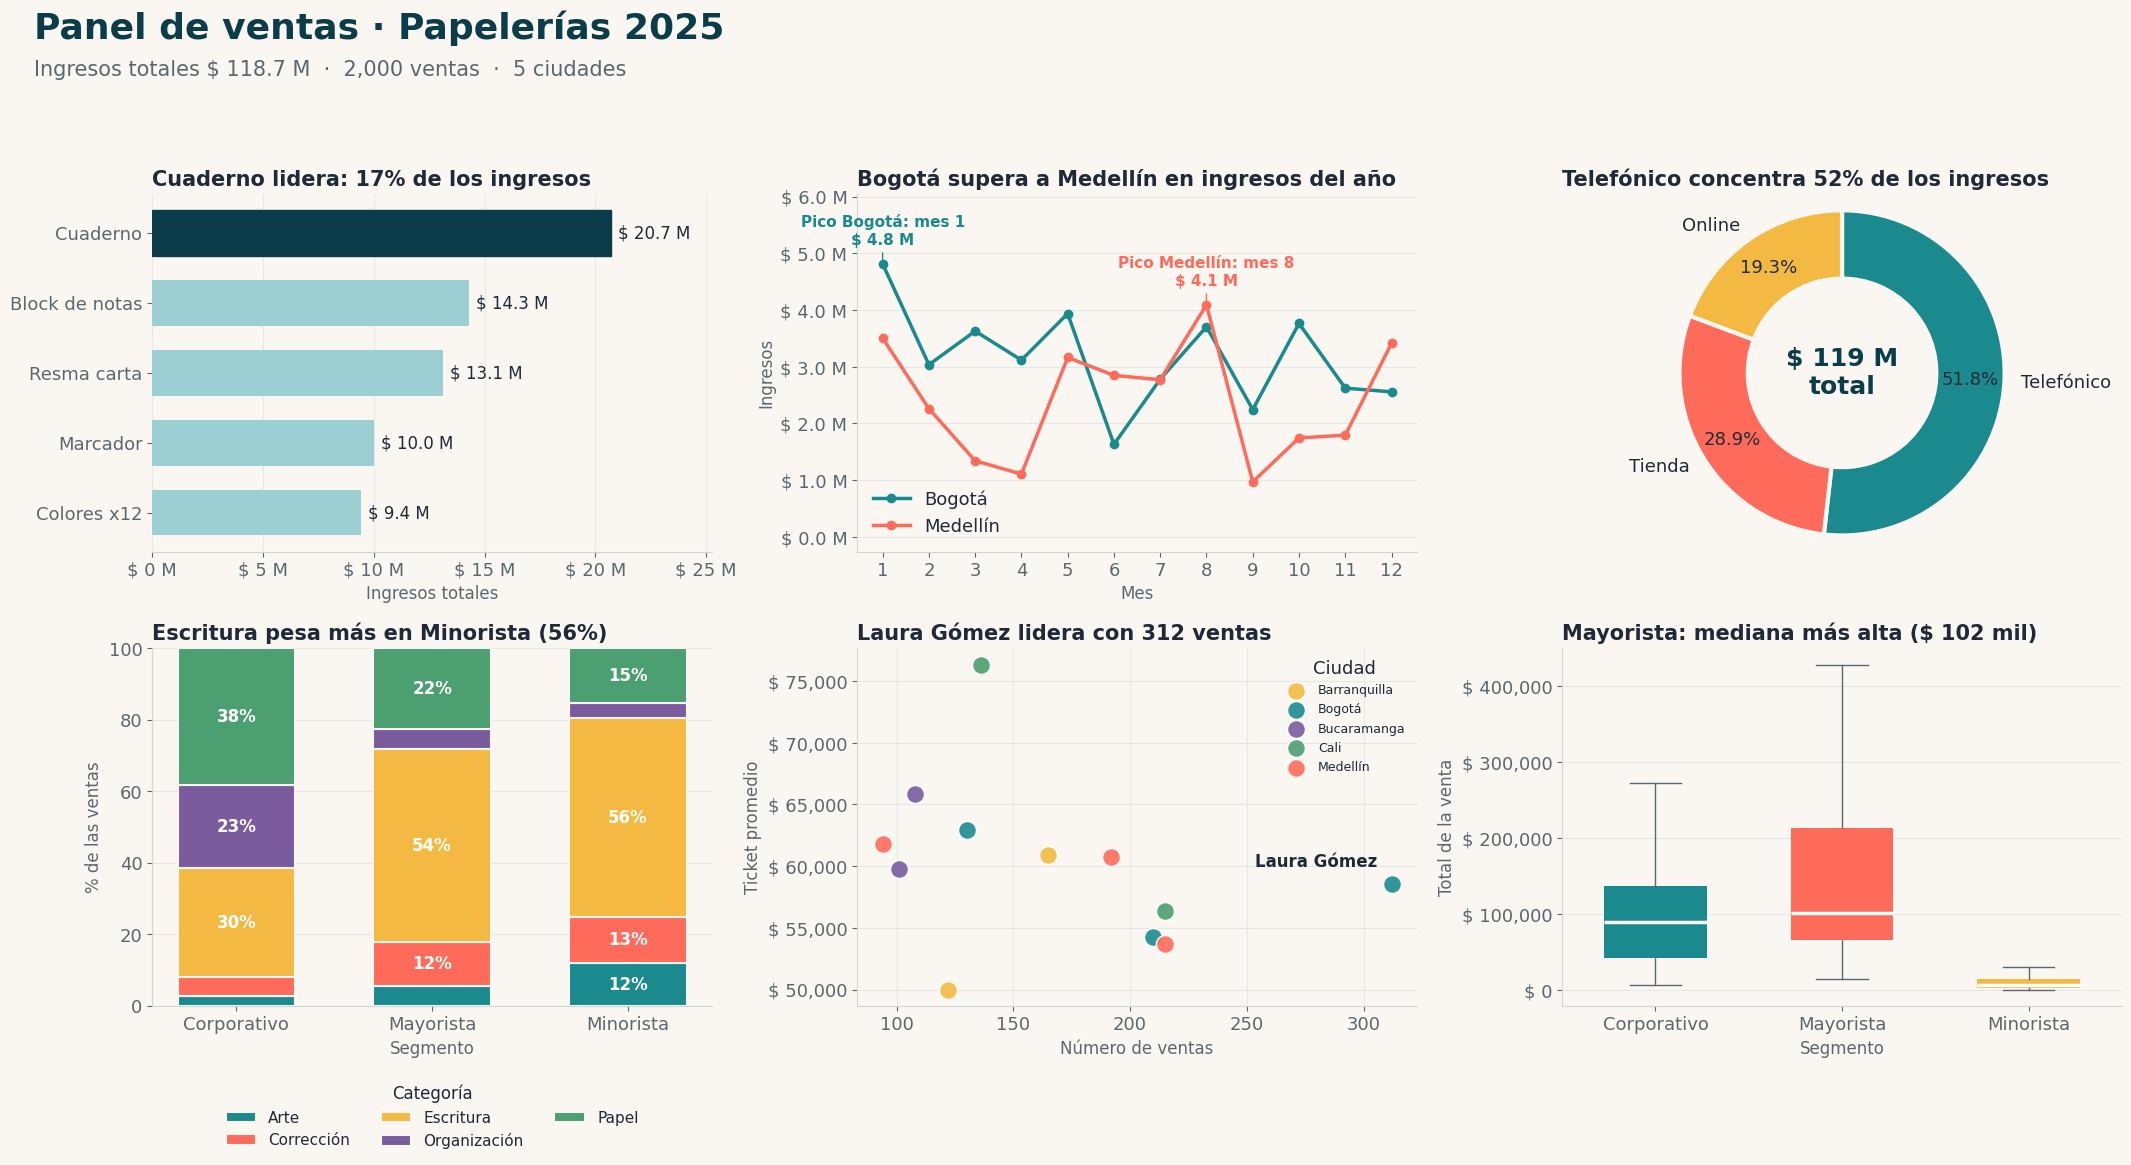

In [24]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [25]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [26]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [27]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "El canal Telefónico genera $ 61,5 M de los $ 118,7 M de ingresos: el 51,8 % de la cadena.",
    "El Cuaderno es el producto líder con $ 20,7 M en ingresos, el 17,5 % del total vendido en 2025.",
    "Los clientes Corporativos compran Organización en un 23,3 % de sus ventas, frente a solo 4,3 % en Minorista.",
]

In [28]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

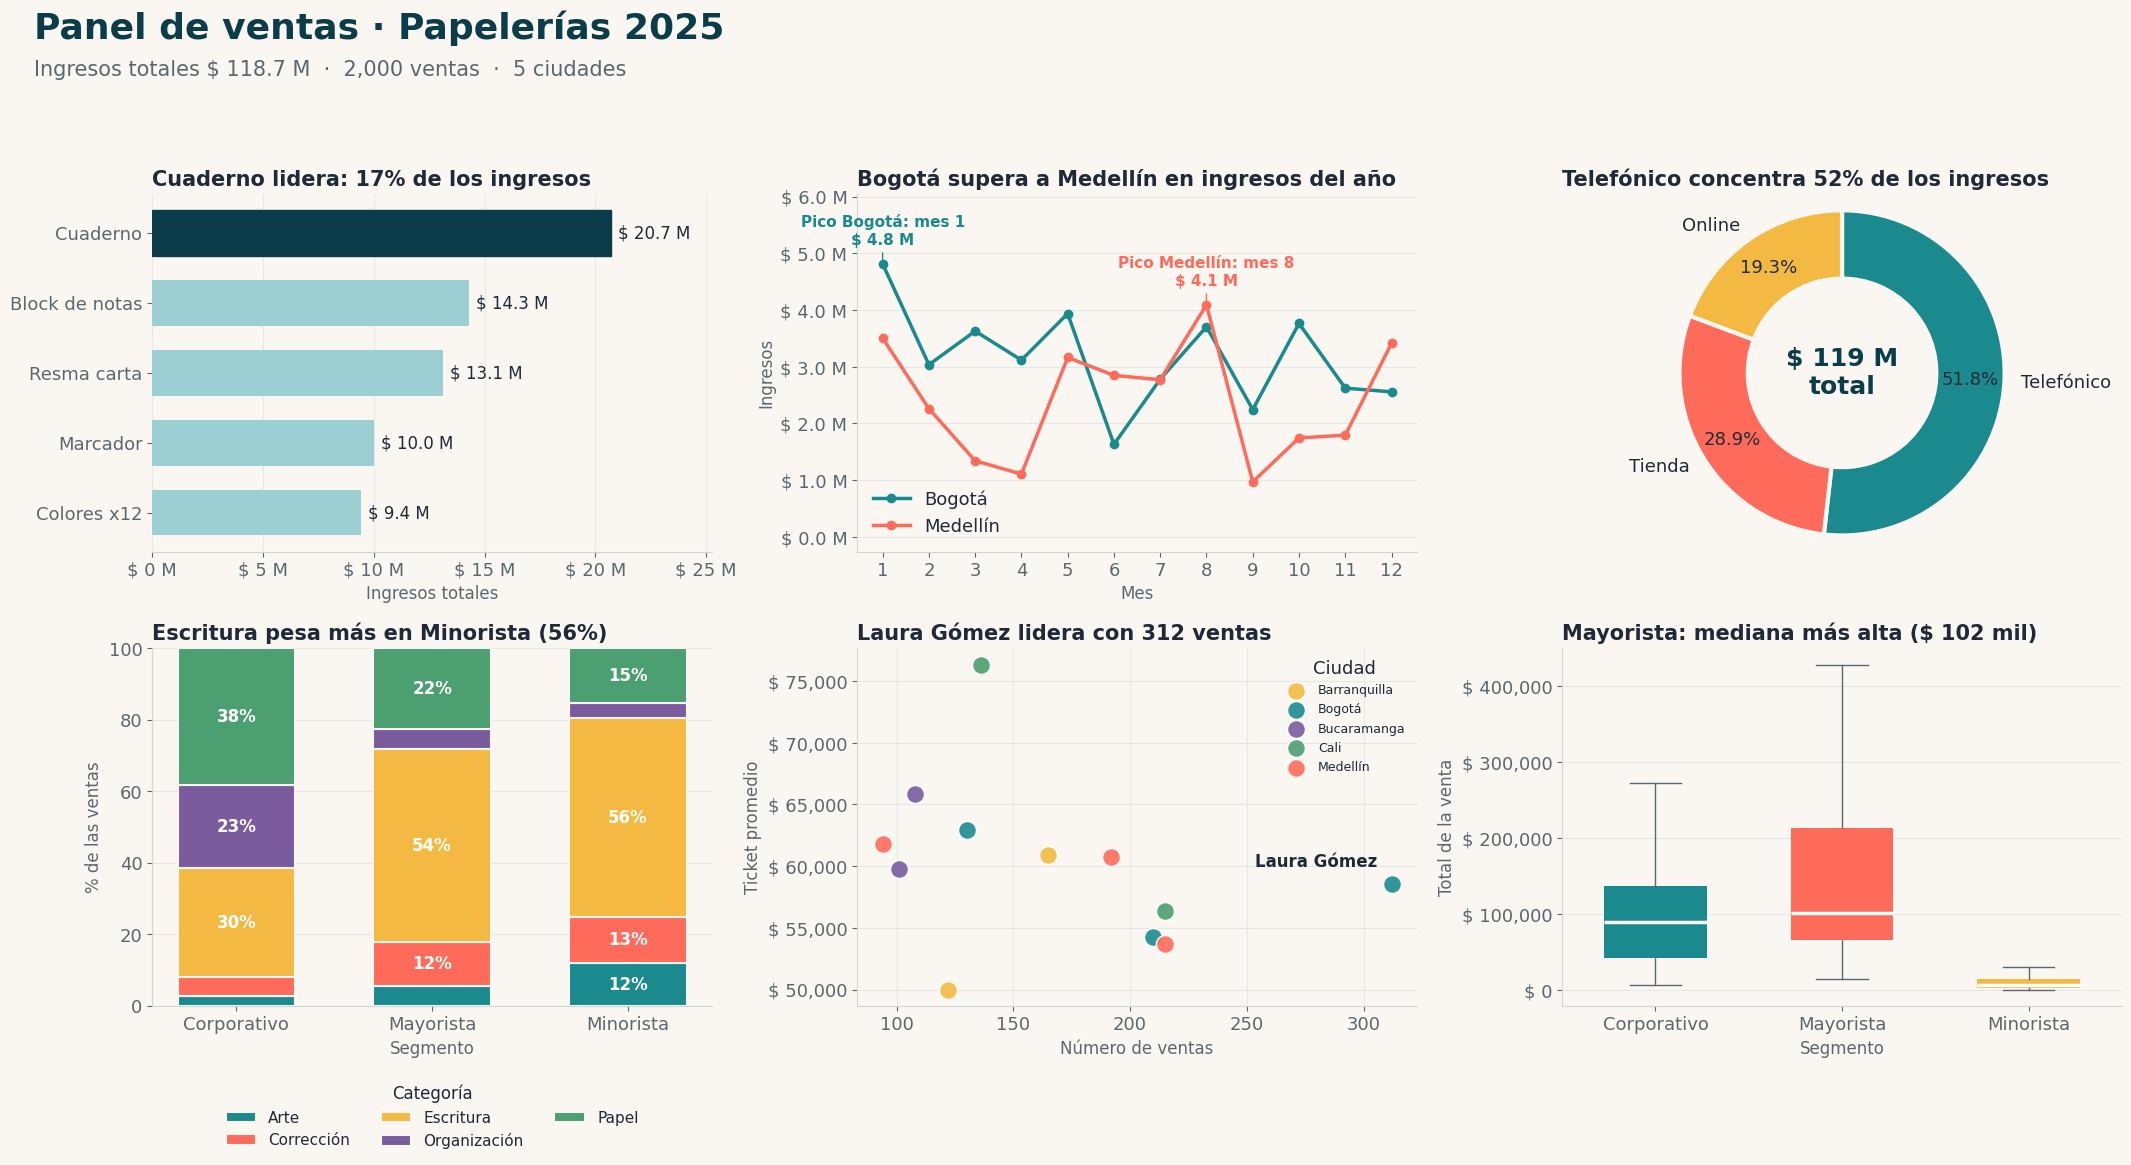

Hallazgos:
• El canal Telefónico genera $ 61,5 M de los $ 118,7 M de ingresos: el 51,8 % de la cadena.
• El Cuaderno es el producto líder con $ 20,7 M en ingresos, el 17,5 % del total vendido en 2025.
• Los clientes Corporativos compran Organización en un 23,3 % de sus ventas, frente a solo 4,3 % en Minorista.


In [29]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.

---
## Entrega: prompts y reflexión

**prompt_v1** — público y objetivo (junta directiva), paleta azul/naranja con fondo claro, títulos que dicen la conclusión, ejes en "$ M" y limpieza visual (sin bordes, cuadrícula suave, valores sobre las barras).

**prompt_v2** — `prompt_v1` + ajustes: paleta verde azulado/coral/ámbar con fondo crema, letras más grandes, dona en lugar del pie con el total en el centro, anotación del mes pico en el gráfico de líneas y Top 5 con la barra líder resaltada.

**Qué tuvimos que corregir de lo que hizo la IA y cómo lo pedimos** *(edita estas líneas si tu experiencia fue distinta)*:
1. Los títulos largos se cortaban (sobre todo el del boxplot): pedimos que ese título fuera corto y que todos los títulos se calcularan con los datos, sin cifras escritas a mano.
2. Las etiquetas del eje de ingresos salían repetidas ("$ 2 M", "$ 2 M"): pedimos usar un decimal en el eje del gráfico de líneas ("$ 1,5 M").
3. La anotación del mes pico tapaba el título del gráfico: pedimos que el texto quedara debajo del título, con una línea fina hacia el punto y más margen vertical.